# 6BUIS017W CWK1 – Task 3: Business Intelligence and Critical Review
Loads the Task 1 and Task 2 outputs from the GitHub repository, compares the two segmentations
(profiles, sector composition, return dependencies) and builds the proposed data mart in SQLite
(star schema, following the Week 2 SQLite RFM tutorial).

In [2]:
# Setup: upload the Task 1 and Task 2 files
import os, json, sqlite3, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

for folder in ["data", "outputs", "figures"]:
    os.makedirs(folder, exist_ok=True)

# Files this notebook needs, and the folder each one belongs in
needed = {
    "raw_daily_2021_2024.parquet": "data",
    "metadata.json": "data",
    "sp500_constituents.csv": "data",
    "feature_table_with_clusters.csv": "outputs",
    "validation_checks.csv": "outputs",
    "high_volume_event_flags.parquet": "outputs",
}

missing = [f for f, d in needed.items() if not os.path.exists(f"{d}/{f}")]
if missing:
    from google.colab import files
    print("Please upload these files:", missing)
    uploaded = files.upload()   # select all six files at once (Ctrl+click)
    for name in uploaded:
        clean = name.replace(" (1)", "").replace(" (2)", "")   # fix browser-renamed downloads
        if clean in needed:
            os.replace(name, f"{needed[clean]}/{clean}")

print("All files ready:", all(os.path.exists(f"{d}/{f}") for f, d in needed.items()))

All files ready: True


In [3]:
# Load Task 1 and Task 2 results
ft = pd.read_csv("outputs/feature_table_with_clusters.csv", index_col="Ticker", parse_dates=["last_event_date"])
raw = pd.read_parquet("data/raw_daily_2021_2024.parquet")
raw.index = pd.to_datetime(raw.index)
meta = json.load(open("data/metadata.json"))
constituents = pd.read_csv("data/sp500_constituents.csv")
validation = pd.read_csv("outputs/validation_checks.csv", index_col="Ticker")
events = pd.read_parquet("outputs/high_volume_event_flags.parquet")
events.index = pd.to_datetime(events.index)

shares = ft.index.tolist()
print("Shares with cluster labels:", len(shares))
print("Solutions available:", [c for c in ft.columns if c.endswith(("Ward", "KMeans"))])
print("Observation date:", meta["observation_date"])

Shares with cluster labels: 486
Solutions available: ['RR_Ward', 'RR_KMeans', 'RFM_Ward', 'RFM_KMeans', 'RF_Ward']
Observation date: 2024-12-31


## 3.2.1 Cluster profiles and sector composition

In [4]:
# 3.2.1a  Cluster profiles side by side (original units)
def profile(sol):
    g = ft.groupby(sol)
    return pd.DataFrame({
        "n_shares": g.size(),
        "mean_weekly_return_%": (g["mean_weekly_return"].mean() * 100).round(3),
        "weekly_beta": g["weekly_beta"].mean().round(2),
        "R_days_median": g["R_days"].median(),
        "F_mean": g["F_events_60"].mean().round(2),
        "M_median_$bn": (g["M_traded_value_usd"].median() / 1e9).round(2),
    })

prof_rr, prof_rfm = profile("RR_Ward"), profile("RFM_Ward")
print("Risk-return clusters (Ward)\n", prof_rr)
print("\nRFM clusters (Ward)\n", prof_rfm)

# Do the two segmentations group the same shares? (ARI near 0 = unrelated groupings)
ari_rr_rfm = adjusted_rand_score(ft["RR_Ward"], ft["RFM_Ward"])
cross = pd.crosstab(ft["RR_Ward"], ft["RFM_Ward"], margins=True)
print(f"\nARI risk-return Ward vs RFM Ward: {ari_rr_rfm:.3f}")
print("Risk-return Ward (rows) vs RFM Ward (columns)\n", cross)

Risk-return clusters (Ward)
          n_shares  mean_weekly_return_%  weekly_beta  R_days_median  F_mean  \
RR_Ward                                                                       
1             394                 0.205          0.9           11.0    2.94   
2              92                 0.632          1.3           11.0    3.20   

         M_median_$bn  
RR_Ward                
1               15.33  
2               24.18  

RFM clusters (Ward)
           n_shares  mean_weekly_return_%  weekly_beta  R_days_median  F_mean  \
RFM_Ward                                                                       
1              404                 0.286         0.97           11.0    3.17   
2               82                 0.286         1.01           54.5    2.10   

          M_median_$bn  
RFM_Ward                
1                16.05  
2                17.85  

ARI risk-return Ward vs RFM Ward: 0.029
Risk-return Ward (rows) vs RFM Ward (columns)
 RFM_Ward    1   2  All
RR_W

Sector mix of all 486 shares (%)
 GICS Sector
Industrials               16.0
Information Technology    15.2
Financials                15.2
Health Care               11.9
Consumer Discretionary     9.7
Consumer Staples           6.6
Utilities                  6.2
Real Estate                6.2
Materials                  4.7
Communication Services     4.1
Energy                     4.1
Name: proportion, dtype: float64

Risk-return Ward – sector % within each cluster
 RR_Ward                    1     2
GICS Sector                       
Communication Services   3.8   5.4
Consumer Discretionary   9.1  12.0
Consumer Staples         8.1   0.0
Energy                   4.1   4.3
Financials              15.5  14.1
Health Care             14.2   2.2
Industrials             14.5  22.8
Information Technology  11.4  31.5
Materials                5.1   3.3
Real Estate              6.9   3.3
Utilities                7.4   1.1

RFM Ward – sector % within each cluster
 RFM_Ward                   1     

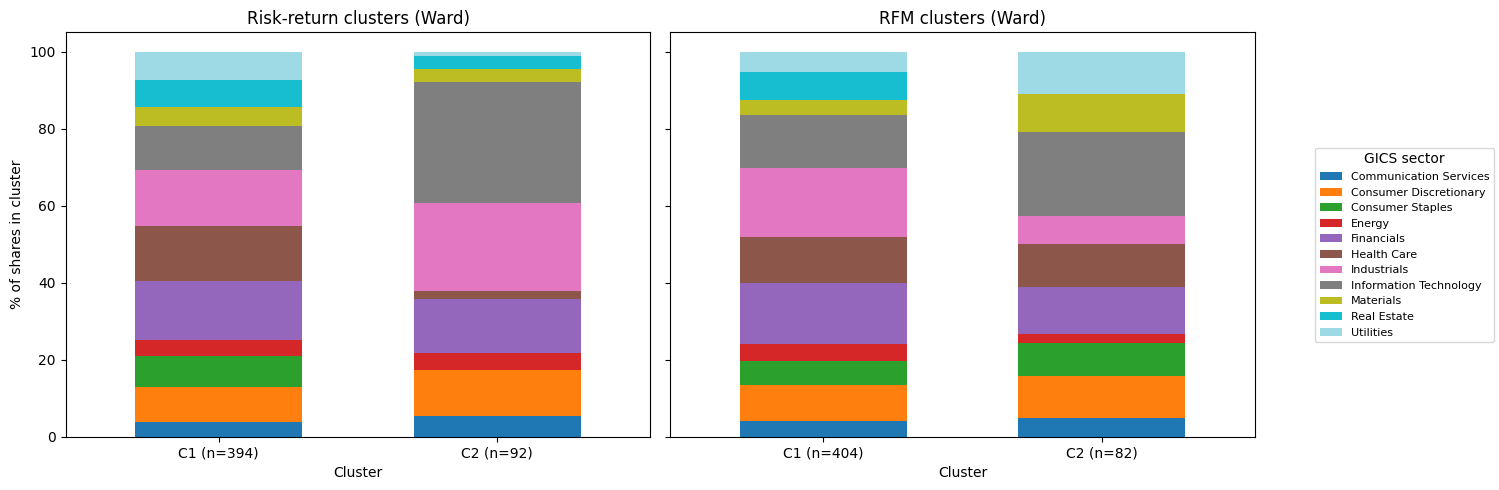

In [5]:
# 3.2.1b  Sector composition of each segmentation
sector = "GICS Sector"
comp_rr = pd.crosstab(ft["RR_Ward"], ft[sector], normalize="index").mul(100).round(1)
comp_rfm = pd.crosstab(ft["RFM_Ward"], ft[sector], normalize="index").mul(100).round(1)
overall = ft[sector].value_counts(normalize=True).mul(100).round(1)
print("Sector mix of all 486 shares (%)\n", overall)
print("\nRisk-return Ward – sector % within each cluster\n", comp_rr.T)
print("\nRFM Ward – sector % within each cluster\n", comp_rfm.T)

# Over/under-representation: cluster share of a sector minus the overall share (percentage points)
diff_rr = comp_rr.sub(overall, axis=1).round(1)
diff_rfm = comp_rfm.sub(overall, axis=1).round(1)
for name, d in [("Risk-return", diff_rr), ("RFM", diff_rfm)]:
    for c in d.index:
        top = d.loc[c].sort_values()
        print(f"{name} cluster {c}: most over-represented {top.index[-1]} (+{top.iloc[-1]} pp), "
              f"most under-represented {top.index[0]} ({top.iloc[0]} pp)")

# Stacked bar chart of sector composition for both segmentations
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, comp, title in [(axes[0], comp_rr, "Risk-return clusters (Ward)"), (axes[1], comp_rfm, "RFM clusters (Ward)")]:
    comp.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.6, legend=False)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_xticklabels([f"C{c} (n={int((ft[comp.index.name] == c).sum())})" for c in comp.index], rotation=0)
axes[0].set_ylabel("% of shares in cluster")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", fontsize=8, title="GICS sector")
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig("figures/fig9_sector_composition.png", dpi=150)
plt.show()

## 3.2.3 Return dependencies
Average pairwise correlation of weekly returns inside each cluster, and correlation between cluster average returns.

In [6]:
# 3.2.3  Return dependencies inside and between clusters
# Rebuild weekly returns exactly as in Task 1 (Friday weeks, last price, complete weeks only, no filling)
START, END = "2021-01-01", "2025-01-01"
calendar = raw["Adj Close"]["^GSPC"].dropna().index
daily = raw["Adj Close"].loc[calendar, shares + ["^GSPC"]]
weekly = daily.resample("W-FRI").last()
complete = ((weekly.index - pd.Timedelta(days=4)) >= pd.Timestamp(START)) & (weekly.index <= pd.Timestamp(END) - pd.Timedelta(days=1))
wret = weekly.loc[complete].pct_change(fill_method=None).iloc[1:]
assert wret.notna().all().all() and len(wret) == int(ft["n_weeks"].iloc[0])
check = (wret[shares].mean() - ft["mean_weekly_return"]).abs().max()
print("Weekly returns rebuilt:", wret.shape, "| max difference vs Task 1 mean return:", f"{check:.2e}")

corr = wret[shares].corr()
def avg_pairwise(tickers):
    c = corr.loc[tickers, tickers].values
    return c[np.triu_indices_from(c, k=1)].mean()

dep_rows = [{"group": "All 486 shares", "n": len(shares), "avg_pairwise_corr": avg_pairwise(shares)}]
for sol in ["RR_Ward", "RFM_Ward"]:
    for c in sorted(ft[sol].unique()):
        members = ft.index[ft[sol] == c].tolist()
        dep_rows.append({"group": f"{sol} cluster {c}", "n": len(members), "avg_pairwise_corr": avg_pairwise(members)})
dependency = pd.DataFrame(dep_rows).round(3)
print(dependency.to_string(index=False))

# Equal-weighted weekly return of each cluster, and how these move together and with the market
port = pd.DataFrame({f"RR C{c}": wret[ft.index[ft["RR_Ward"] == c]].mean(axis=1) for c in sorted(ft["RR_Ward"].unique())})
for c in sorted(ft["RFM_Ward"].unique()):
    port[f"RFM C{c}"] = wret[ft.index[ft["RFM_Ward"] == c]].mean(axis=1)
port["S&P 500"] = wret["^GSPC"]
port_corr = port.corr().round(3)
print("\nCorrelation of cluster average weekly returns\n", port_corr)

Weekly returns rebuilt: (207, 487) | max difference vs Task 1 mean return: 9.91e-17
             group   n  avg_pairwise_corr
    All 486 shares 486              0.300
 RR_Ward cluster 1 394              0.297
 RR_Ward cluster 2  92              0.374
RFM_Ward cluster 1 404              0.306
RFM_Ward cluster 2  82              0.266

Correlation of cluster average weekly returns
          RR C1  RR C2  RFM C1  RFM C2  S&P 500
RR C1    1.000  0.897   0.993   0.979    0.923
RR C2    0.897  1.000   0.940   0.932    0.931
RFM C1   0.993  0.940   1.000   0.980    0.941
RFM C2   0.979  0.932   0.980   1.000    0.943
S&P 500  0.923  0.931   0.941   0.943    1.000


## 3.1 Data mart (SQLite star schema)

In [7]:
# 3.1  Build the data mart in SQLite
DB = "outputs/sp500_rfm_datamart.sqlite"
if os.path.exists(DB):
    os.remove(DB)
conn = sqlite3.connect(DB)

# Dimensions
dim_date = pd.DataFrame({"date": calendar})
dim_date["date_key"] = dim_date["date"].dt.strftime("%Y%m%d").astype(int)
dim_date["year"] = dim_date["date"].dt.year
dim_date["quarter"] = dim_date["date"].dt.quarter
dim_date["month"] = dim_date["date"].dt.month
dim_date["week_ending_fri"] = dim_date["date"].dt.to_period("W-FRI").dt.end_time.dt.strftime("%Y-%m-%d")
dim_date["date"] = dim_date["date"].dt.strftime("%Y-%m-%d")

sectors = sorted(ft[sector].dropna().unique())
dim_sector = pd.DataFrame({"sector_key": range(1, len(sectors) + 1), "gics_sector": sectors})

dim_share = validation.reset_index()[["Ticker", "Security", "GICS Sector", "Date added", "status", "reason"]].copy()
dim_share.columns = ["ticker", "security", "gics_sector", "date_added", "inclusion_status", "exclusion_reason"]
dim_share.insert(0, "share_key", range(1, len(dim_share) + 1))
dim_share = dim_share.merge(dim_sector, on="gics_sector", how="left").drop(columns="gics_sector")

dim_benchmark = pd.DataFrame({"benchmark_key": [1], "ticker": ["^GSPC"], "name": ["S&P 500 index"],
                              "price_basis": ["Price index (no dividends); Adj Close = Close"]})

dim_calc_version = pd.DataFrame([{
    "version_key": 1, "version_label": "CWK1 v1.0",
    "ticker_source": meta.get("ticker_source"), "ticker_retrieval_date": meta.get("ticker_retrieval_date"),
    "price_source": meta.get("price_source"), "price_download_date": meta.get("price_download_date"),
    "study_period": meta.get("study_period", f"{START} to {END} (end exclusive)"),
    "observation_date": meta["observation_date"], "rfm_window": meta.get("rfm_window"),
    "event_rule": "Volume > 2 x mean of preceding 20 sessions (current day excluded)",
    "return_rule": "W-FRI last Adj Close; complete weeks only; no filling",
    "clustering": "StandardScaler; Ward (Euclidean) and K-means (seed 42, n_init 50); k=2; log1p(M)",
    "code_reference": "CWK1_Task1_Data_Preparation.ipynb, CWK1_Task2_Segmentation.ipynb",
    "package_versions": json.dumps(meta.get("package_versions", {})),
}])

# --- Facts ---
key_of = dict(zip(dim_share["ticker"], dim_share["share_key"]))
long = (raw[["Close", "Adj Close", "Volume", "Dividends", "Stock Splits"]].loc[calendar]
        .stack(level=1, future_stack=True))
long.index.names = ["date", "ticker"]
long = long.rename(columns={"Close": "close", "Adj Close": "adj_close", "Volume": "volume",
                            "Dividends": "dividend", "Stock Splits": "split_ratio"}).reset_index()
long = long[long["ticker"].isin(shares)].copy()
ev = events.loc[:, events.columns.isin(shares)].stack().rename("high_volume_flag").reset_index()
ev.columns = ["date", "ticker", "high_volume_flag"]
long = long.merge(ev, on=["date", "ticker"], how="left")
long["date_key"] = long["date"].dt.strftime("%Y%m%d").astype(int)
long["share_key"] = long["ticker"].map(key_of)
fact_daily_share = long[["date_key", "share_key", "close", "adj_close", "volume", "dividend", "split_ratio", "high_volume_flag"]]

bench = raw.loc[calendar, [("Close", "^GSPC"), ("Adj Close", "^GSPC")]]
bench.columns = ["close", "adj_close"]
fact_daily_benchmark = bench.reset_index().rename(columns={"Date": "date", "index": "date"})
fact_daily_benchmark["date_key"] = pd.to_datetime(fact_daily_benchmark.iloc[:, 0]).dt.strftime("%Y%m%d").astype(int)
fact_daily_benchmark["benchmark_key"] = 1
fact_daily_benchmark = fact_daily_benchmark[["date_key", "benchmark_key", "close", "adj_close"]]

fact_share_metrics = ft.reset_index()[["Ticker", "n_weeks", "mean_weekly_return", "weekly_beta", "beta_se",
                                       "last_event_date", "R_days", "F_events_60", "M_traded_value_usd"]].copy()
fact_share_metrics["last_event_date"] = fact_share_metrics["last_event_date"].dt.strftime("%Y-%m-%d")
fact_share_metrics.insert(0, "share_key", fact_share_metrics.pop("Ticker").map(key_of))
fact_share_metrics.insert(1, "version_key", 1)
fact_share_metrics.insert(2, "benchmark_key", 1)

sol_k = {"RR_Ward": "risk_return", "RR_KMeans": "risk_return", "RFM_Ward": "rfm", "RFM_KMeans": "rfm", "RF_Ward": "rf_only"}
fact_cluster = (ft[list(sol_k)].reset_index().melt(id_vars="Ticker", var_name="solution", value_name="cluster"))
fact_cluster["feature_set"] = fact_cluster["solution"].map(sol_k)
fact_cluster["algorithm"] = np.where(fact_cluster["solution"].str.contains("KMeans"), "kmeans", "ward")
fact_cluster["k"] = fact_cluster.groupby("solution")["cluster"].transform("nunique")
fact_cluster.insert(0, "share_key", fact_cluster.pop("Ticker").map(key_of))
fact_cluster.insert(1, "version_key", 1)

tables = {"dim_date": dim_date, "dim_share": dim_share, "dim_sector": dim_sector, "dim_benchmark": dim_benchmark,
          "dim_calc_version": dim_calc_version, "fact_daily_share": fact_daily_share,
          "fact_daily_benchmark": fact_daily_benchmark, "fact_share_metrics": fact_share_metrics,
          "fact_cluster_assignment": fact_cluster}
for name, tbl in tables.items():
    tbl.to_sql(name, conn, if_exists="replace", index=False)
conn.commit()

mart_summary = pd.DataFrame([{"table": n, "rows": len(t), "columns": ", ".join(t.columns)} for n, t in tables.items()])
print(mart_summary[["table", "rows"]].to_string(index=False))
print("Database size (MB):", round(os.path.getsize(DB) / 1e6, 1))

                  table   rows
               dim_date   1005
              dim_share    503
             dim_sector     11
          dim_benchmark      1
       dim_calc_version      1
       fact_daily_share 488430
   fact_daily_benchmark   1005
     fact_share_metrics    486
fact_cluster_assignment   2430
Database size (MB): 19.9


In [8]:
# 3.1  Example query: the data mart answers a stakeholder question with one SQL join
q = """
SELECT c.solution, c.cluster, s.gics_sector, COUNT(*) AS n_shares,
       ROUND(AVG(m.weekly_beta), 2) AS avg_beta,
       ROUND(AVG(m.mean_weekly_return) * 100, 3) AS avg_weekly_return_pct,
       ROUND(AVG(m.M_traded_value_usd) / 1e9, 1) AS avg_traded_value_bn
FROM fact_cluster_assignment c
JOIN dim_share sh          ON sh.share_key = c.share_key
JOIN dim_sector s          ON s.sector_key = sh.sector_key
JOIN fact_share_metrics m  ON m.share_key = c.share_key AND m.version_key = c.version_key
WHERE c.solution = 'RR_Ward'
GROUP BY c.solution, c.cluster, s.gics_sector
ORDER BY c.cluster, n_shares DESC
LIMIT 10;
"""
example_query = pd.read_sql(q, conn)
print(example_query.to_string(index=False))

# Check the mart reproduces the notebook figures (row counts)
chk = pd.read_sql("SELECT COUNT(DISTINCT share_key) AS shares, COUNT(*) AS daily_rows FROM fact_daily_share", conn)
print("\nMart check:", chk.to_dict("records"), "| expected shares:", len(shares), "x trading days:", len(calendar))

solution  cluster            gics_sector  n_shares  avg_beta  avg_weekly_return_pct  avg_traded_value_bn
 RR_Ward        1             Financials        61      0.92                  0.272                 24.1
 RR_Ward        1            Industrials        57      0.94                  0.230                 20.2
 RR_Ward        1            Health Care        56      0.81                  0.107                 27.0
 RR_Ward        1 Information Technology        45      1.34                  0.200                 41.6
 RR_Ward        1 Consumer Discretionary        36      1.14                  0.246                 88.7
 RR_Ward        1       Consumer Staples        32      0.52                  0.103                 26.5
 RR_Ward        1              Utilities        29      0.55                  0.197                 13.0
 RR_Ward        1            Real Estate        27      0.90                  0.168                 11.6
 RR_Ward        1              Materials        20     

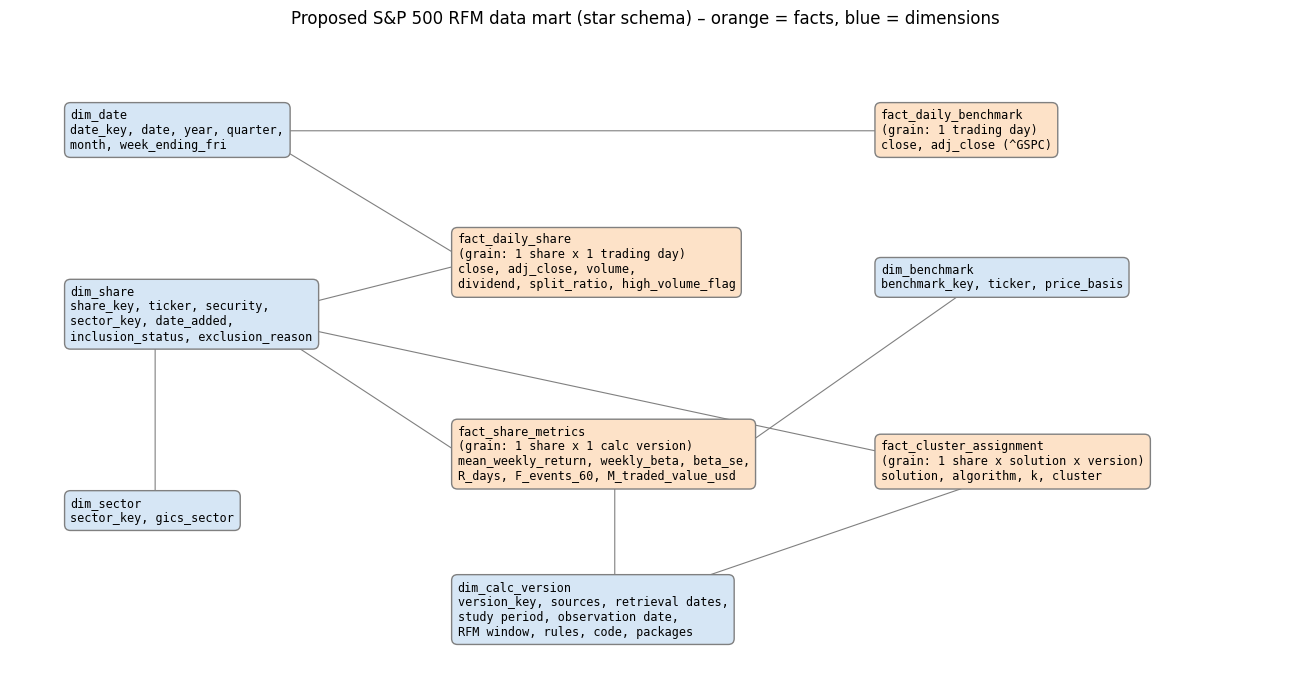

In [9]:
# 3.1  Star schema diagram
fig, ax = plt.subplots(figsize=(13, 7))
ax.axis("off")
boxes = {
    "fact_daily_share\n(grain: 1 share x 1 trading day)\nclose, adj_close, volume,\ndividend, split_ratio, high_volume_flag": (0.37, 0.55, "#fde2c8"),
    "fact_share_metrics\n(grain: 1 share x 1 calc version)\nmean_weekly_return, weekly_beta, beta_se,\nR_days, F_events_60, M_traded_value_usd": (0.37, 0.18, "#fde2c8"),
    "fact_cluster_assignment\n(grain: 1 share x solution x version)\nsolution, algorithm, k, cluster": (0.72, 0.18, "#fde2c8"),
    "fact_daily_benchmark\n(grain: 1 trading day)\nclose, adj_close (^GSPC)": (0.72, 0.82, "#fde2c8"),
    "dim_date\ndate_key, date, year, quarter,\nmonth, week_ending_fri": (0.05, 0.82, "#d6e6f5"),
    "dim_share\nshare_key, ticker, security,\nsector_key, date_added,\ninclusion_status, exclusion_reason": (0.05, 0.45, "#d6e6f5"),
    "dim_sector\nsector_key, gics_sector": (0.05, 0.1, "#d6e6f5"),
    "dim_benchmark\nbenchmark_key, ticker, price_basis": (0.72, 0.55, "#d6e6f5"),
    "dim_calc_version\nversion_key, sources, retrieval dates,\nstudy period, observation date,\nRFM window, rules, code, packages": (0.37, -0.12, "#d6e6f5"),
}
for text, (x, y, colour) in boxes.items():
    ax.text(x, y, text, fontsize=8.5, va="bottom", ha="left", family="monospace",
            bbox=dict(boxstyle="round,pad=0.5", fc=colour, ec="grey"), zorder=3)
links = [((0.2, 0.86), (0.37, 0.62)), ((0.2, 0.86), (0.72, 0.86)), ((0.2, 0.5), (0.37, 0.6)),
         ((0.2, 0.5), (0.37, 0.24)), ((0.2, 0.5), (0.72, 0.24)), ((0.12, 0.14), (0.12, 0.45)),
         ((0.82, 0.6), (0.6, 0.24)), ((0.5, -0.02), (0.5, 0.18)), ((0.55, -0.02), (0.8, 0.18))]
for (x1, y1), (x2, y2) in links:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-", color="grey", lw=0.8), zorder=1)
ax.set_xlim(0, 1.05); ax.set_ylim(-0.2, 1.05)
ax.set_title("Proposed S&P 500 RFM data mart (star schema) – orange = facts, blue = dimensions")
plt.tight_layout()
plt.savefig("figures/fig10_datamart_schema.png", dpi=150)
plt.show()

## Report numbers and report tables

In [10]:
# Report numbers and report tables for Task 3
rn = {
    "ARI risk-return Ward vs RFM Ward": round(ari_rr_rfm, 3),
    "Avg pairwise corr all shares": dependency.loc[0, "avg_pairwise_corr"],
}
for _, r in dependency.iloc[1:].iterrows():
    rn[f"Avg pairwise corr {r['group']}"] = r["avg_pairwise_corr"]
rr_ids = sorted(ft["RR_Ward"].unique())
rn["Corr RR C1 vs RR C2 portfolios"] = port_corr.loc[f"RR C{rr_ids[0]}", f"RR C{rr_ids[-1]}"]
for col in port.columns[:-1]:
    rn[f"Corr {col} portfolio vs S&P 500"] = port_corr.loc[col, "S&P 500"]
for name, d in [("RR", diff_rr), ("RFM", diff_rfm)]:
    for c in d.index:
        top = d.loc[c].sort_values()
        rn[f"{name} C{c} over / under sector (pp)"] = f"{top.index[-1]} +{top.iloc[-1]} / {top.index[0]} {top.iloc[0]}"
rn["Data mart rows (daily fact)"] = len(fact_daily_share)
rn["Data mart size MB"] = round(os.path.getsize(DB) / 1e6, 1)
for k, v in rn.items():
    print(f"{k:45s}: {v}")
pd.Series(rn).to_csv("outputs/report_numbers_task3.csv")

with pd.ExcelWriter("outputs/report_tables_task3.xlsx") as w:
    pd.concat({"Risk-return (Ward)": prof_rr, "RFM (Ward)": prof_rfm}).reset_index().rename(
        columns={"level_0": "Segmentation", "level_1": "Cluster"}).to_excel(w, sheet_name="T14_Profiles_compare", index=False)
    cross.reset_index().to_excel(w, sheet_name="T15_RR_vs_RFM_crosstab", index=False)
    comp_rr.T.reset_index().to_excel(w, sheet_name="T16_Sector_RR", index=False)
    comp_rfm.T.reset_index().to_excel(w, sheet_name="T16_Sector_RFM", index=False)
    overall.rename("All shares %").reset_index().to_excel(w, sheet_name="T16_Sector_overall", index=False)
    dependency.to_excel(w, sheet_name="T17_Return_dependency", index=False)
    port_corr.reset_index().to_excel(w, sheet_name="T17_Portfolio_corr", index=False)
    mart_summary.to_excel(w, sheet_name="T18_Data_mart_tables", index=False)
    example_query.to_excel(w, sheet_name="AppF_Example_query", index=False)
print("Saved outputs/report_tables_task3.xlsx")
conn.close()

ARI risk-return Ward vs RFM Ward             : 0.029
Avg pairwise corr all shares                 : 0.3
Avg pairwise corr RR_Ward cluster 1          : 0.297
Avg pairwise corr RR_Ward cluster 2          : 0.374
Avg pairwise corr RFM_Ward cluster 1         : 0.306
Avg pairwise corr RFM_Ward cluster 2         : 0.266
Corr RR C1 vs RR C2 portfolios               : 0.897
Corr RR C1 portfolio vs S&P 500              : 0.923
Corr RR C2 portfolio vs S&P 500              : 0.931
Corr RFM C1 portfolio vs S&P 500             : 0.941
Corr RFM C2 portfolio vs S&P 500             : 0.943
RR C1 over / under sector (pp)               : Health Care +2.3 / Information Technology -3.8
RR C2 over / under sector (pp)               : Information Technology +16.3 / Health Care -9.7
RFM C1 over / under sector (pp)              : Industrials +1.8 / Information Technology -1.3
RFM C2 over / under sector (pp)              : Information Technology +6.8 / Industrials -8.7
Data mart rows (daily fact)               